<a href="https://colab.research.google.com/github/Sattvikannadatha/LLM-Ticket/blob/main/Copy_of_Lending_Club_Loan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Download the exact Lending Club dataset directly from a public repository
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/loan_data.csv"
df = pd.read_csv(url)

# Display the first 5 rows to confirm it loaded correctly
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


/tmp/ipykernel_3328/1455279206.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='not.fully.paid', data=df, palette='viridis')


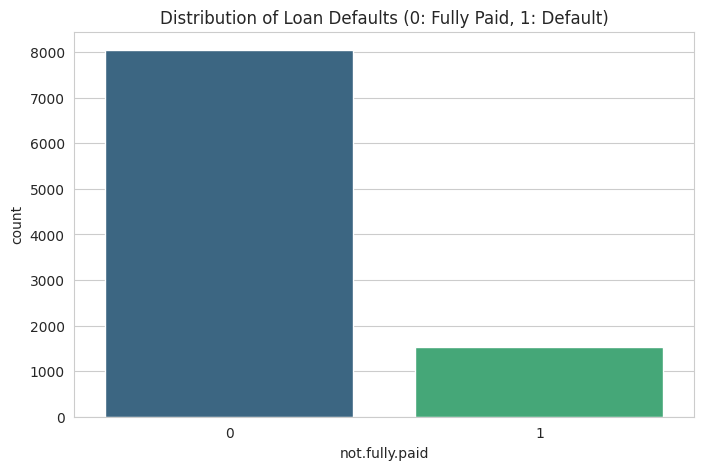

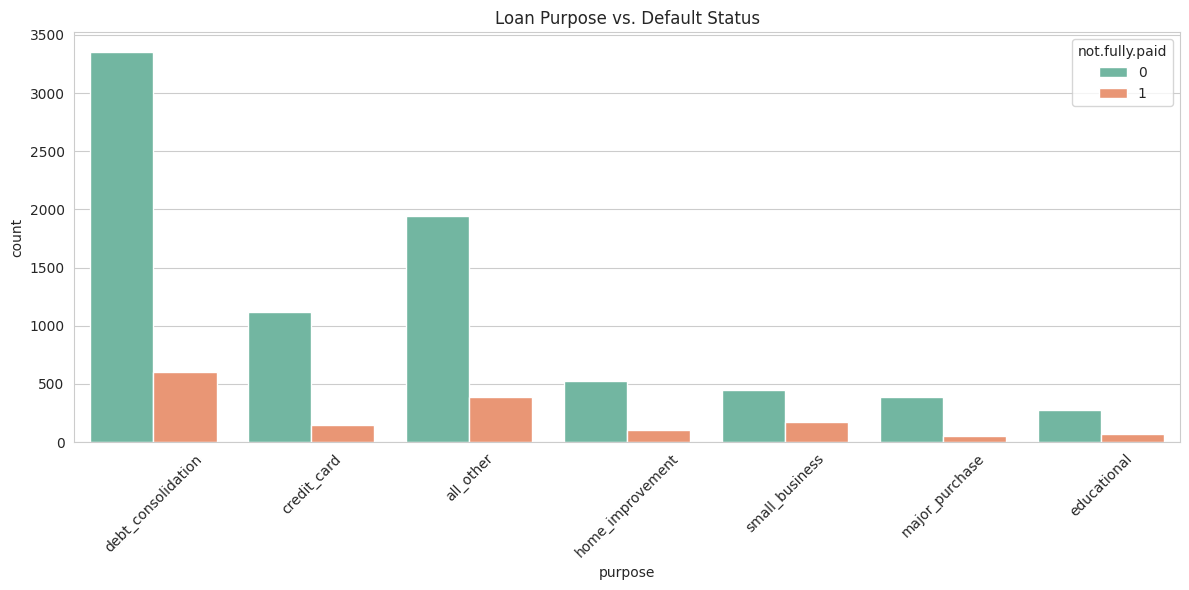

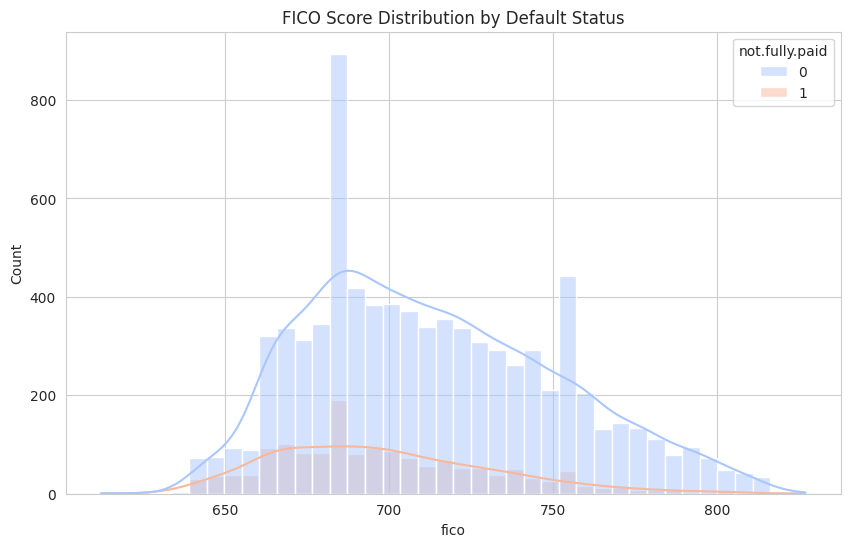

Columns after Feature Transformation:
Index(['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti',
       'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid',
       'purpose_credit_card', 'purpose_debt_consolidation',
       'purpose_educational', 'purpose_home_improvement',
       'purpose_major_purchase', 'purpose_small_business'],
      dtype='object')


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,False,True,False,False,False,False
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,True,False,False,False,False,False
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,False,True,False,False,False,False
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,False,True,False,False,False,False
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,True,False,False,False,False,False


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- TASK 2: Exploratory Data Analysis (EDA) ---
# Set visualization style for better readability
sns.set_style('whitegrid')

# Plot 1: Check the class imbalance in the target variable
plt.figure(figsize=(8, 5))
sns.countplot(x='not.fully.paid', data=df, palette='viridis')
plt.title('Distribution of Loan Defaults (0: Fully Paid, 1: Default)')
plt.show()

# Plot 2: Analyze default rates across different loan purposes
plt.figure(figsize=(12, 6))
sns.countplot(x='purpose', hue='not.fully.paid', data=df, palette='Set2')
plt.title('Loan Purpose vs. Default Status')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 3: FICO score distribution compared to default status
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='fico', hue='not.fully.paid', bins=40, kde=True, palette='coolwarm')
plt.title('FICO Score Distribution by Default Status')
plt.show()

# --- TASK 1: Feature Transformation ---
# The 'purpose' column is categorical text. We must convert it to discrete numerical values using one-hot encoding.
# drop_first=True removes one of the resulting dummy columns to prevent multicollinearity (redundancy).
df_transformed = pd.get_dummies(df, columns=['purpose'], drop_first=True)

# Verify the transformation by displaying the new dataframe structure
print("Columns after Feature Transformation:")
print(df_transformed.columns)
df_transformed.head()

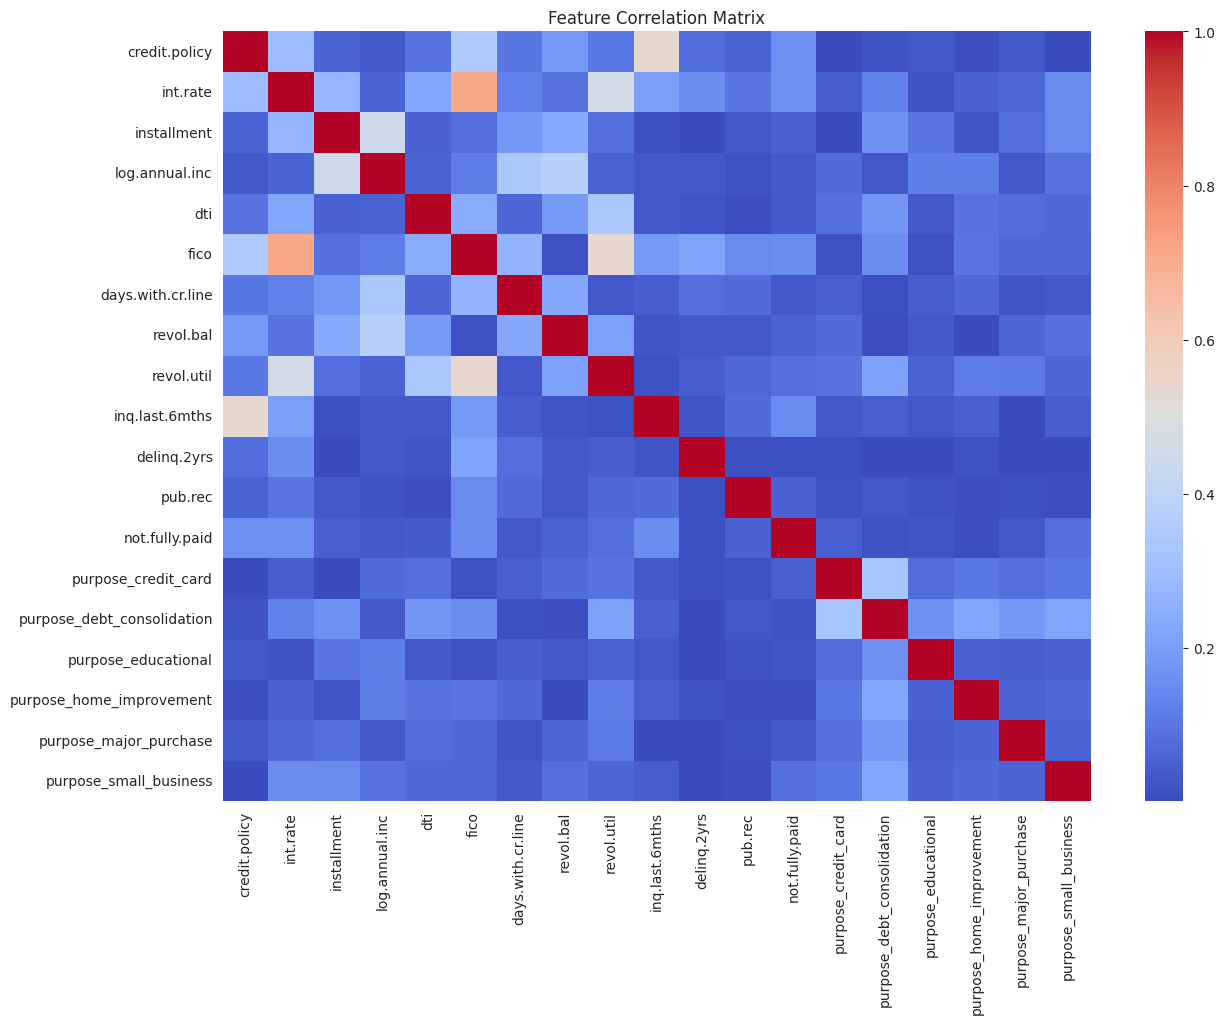

Features flagged for dropping due to high correlation: []
Original feature count: 19
Final feature count for modeling: 19


In [ ]:
import numpy as np

# Calculate the absolute correlation matrix for all numerical features
corr_matrix = df_transformed.corr().abs()

# Plot the heatmap to visually inspect the correlations
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.show()

# Programmatically isolate the upper triangle of the correlation matrix
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Identify any feature columns with a correlation greater than 0.80
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.80)]
print(f"Features flagged for dropping due to high correlation: {to_drop}")

# Drop the highly correlated features to finalize the dataset for the neural network
df_final = df_transformed.drop(columns=to_drop)

print(f"Original feature count: {df_transformed.shape[1]}")
print(f"Final feature count for modeling: {df_final.shape[1]}")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import numpy as np

# 1. Separate Features (X) and Target (y)
X = df_final.drop('not.fully.paid', axis=1).values
y = df_final['not.fully.paid'].values

# 2. Train/Test Split
# stratify=y ensures the imbalanced default ratio is preserved in both the training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Data Scaling
# Neural networks require inputs to be scaled between 0 and 1 to converge properly during training
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Handle Class Imbalance via Class Weights
# Because fully paid loans vastly outnumber defaults, we must weigh the default class heavier.
# This mathematically penalizes the model for missing the rare '1' (default) cases.
neg, pos = np.bincount(y_train)
total = neg + pos
weight_for_0 = (1 / neg) * (total / 2.0)
weight_for_1 = (1 / pos) * (total / 2.0)
class_weights = {0: weight_for_0, 1: weight_for_1}
print(f"Class Weights automatically calculated: {class_weights}")

# 5. Build the Deep Learning Model Architecture
model = Sequential()

# Input Layer & First Hidden Layer
model.add(Dense(78, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.2)) # Dropout randomly turns off neurons to prevent overfitting

# Second Hidden Layer
model.add(Dense(39, activation='relu'))
model.add(Dropout(0.2))

# Third Hidden Layer
model.add(Dense(19, activation='relu'))
model.add(Dropout(0.2))

# Output Layer (Sigmoid activation is required for binary 0/1 classification)
model.add(Dense(1, activation='sigmoid'))

# Compile the model specifying the optimizer and loss function
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 6. Train the Neural Network
print("\nBeginning model training...\n")
history = model.fit(
    x=X_train,
    y=y_train,
    epochs=25, # Set to 25 epochs to train quickly, can be increased to 50 for deeper learning
    batch_size=256,
    validation_data=(X_test, y_test),
    class_weight=class_weights,
    verbose=1
)

# 7. Evaluate the Model's Performance
# Convert the continuous probability output into a hard 0 or 1 prediction using a 0.5 threshold
predictions = (model.predict(X_test) > 0.5).astype("int32")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, predictions))

print("\n--- Classification Report ---")
print(classification_report(y_test, predictions))

Class Weights automatically calculated: {0: np.float64(0.5952454940957116), 1: np.float64(3.1247960848287115)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Beginning model training...

Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.5570 - loss: 0.6873 - val_accuracy: 0.7229 - val_loss: 0.6536
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5955 - loss: 0.6727 - val_accuracy: 0.7197 - val_loss: 0.6451
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6509 - loss: 0.6677 - val_accuracy: 0.7015 - val_loss: 0.6582
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6363 - loss: 0.6631 - val_accuracy: 0.6247 - val_loss: 0.6762
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6434 - loss: 0.6591 - val_accuracy: 0.6268 - val_loss: 0.6668
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6291 - loss: 0.6559 - val_accuracy: 0.6728 - val_loss: 0.6366
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6564 - loss: 0.6547 - val_accuracy: 0.6242 - val_loss: 0.6594
Epoch 8/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6158 - loss: 0.6522 - v